The purpose of this file is to evaluate the system's faithfulness. Since running a single evaluation takes a long time, I will not compare different models here.

In [80]:
from IPython.display import display, Markdown
import pandas as pd
import time

from selenium.webdriver.common.devtools.v152.dom import query_selector
import ast

from rag_flow import RAGFlow
from eval import Eval
from datetime import datetime
from langchain_ollama import ChatOllama
from matplotlib import pyplot as plt
import seaborn as sns

In [81]:
llama = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    verbose=False,
)
classifier = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=15,
    reasoning=False,
    num_ctx=3000,
    verbose=False,
)

In [82]:
params = {
    "query_model": llama,
    "answer_model": llama,
    "titles_limit": 5,
    "top_k_titles": 5,
    "chunk_size": 200,
    "chunk_overlap_fraction": 0.2,
    "candidate_k": 20,
    "top_k_chunks": 10,
    "classifier": classifier
}


rag = RAGFlow(params)

In [86]:
answer = rag.run("How does retrieval-augmented generation reduce hallucinations in large language models??")

2026-10-18 11:36:43,449 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-18 11:36:44,524 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-18 11:36:44,660 | INFO | user prompt: How does retrieval-augmented generation reduce hallucinations in large language models??, web query: retrieval-augmented language generation large language models hallucinations
Batches: 100%|██████████| 14/14 [00:00<00:00, 20.69it/s]


Chunks: 431
Chunk embeddings shape: (431, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 106.85it/s]
2026-10-18 11:36:55,887 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-18 11:36:58,419 | INFO | Answer generation input tokens: 5157


In [87]:
display(Markdown(f"""{answer['answer']}"""))

According to the provided context, retrieval-augmented generation reduces hallucinations in large language models by grounding responses in externally retrieved evidence. This means that the model uses external sources to retrieve relevant information, which helps to reduce the likelihood of generating responses based on personal biases or incomplete knowledge, and instead, provides a more accurate and reliable output. This is mentioned in the context of the RAG framework, which significantly reduces hallucination in large language models by using retrieval to provide additional context. 

Source:
[316] Z. Wang, Z. Wang, L. Le, H. S. Zheng, S. Mishra, V. Perot, Y. Zhang, A. Mattapalli, A. Taly, J. Shang, C.-Y. Lee, and T. Pfister, “Speculative rag: Enhancing retrieval augmented generation through drafting,” 2025. [Online]. Available: https://arxiv.org/abs/2407.08223

In [5]:
eval = Eval(llama)

In [7]:
def extract_answer(x):
    if isinstance(x, dict):
        return x.get("answer", "")
    if isinstance(x, str):
        try:
            parsed = ast.literal_eval(x)
            if isinstance(parsed, dict):
                return parsed.get("answer", "")
        except (ValueError, SyntaxError):
            pass

        return x

    return None

def extract_chunks(x):
    if isinstance(x, str):
        try:
            x = ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return []

    if not isinstance(x, list):
        return []

    chunks = []

    for el in x:
        try:
            if isinstance(el, str):
                el = ast.literal_eval(el)

            if isinstance(el, dict):
                chunks.append(el.get("text", ""))

        except (ValueError, SyntaxError):
            continue

    return chunks




In [8]:
eval_res = []

In [70]:
rag_answers = pd.read_csv("rag_answers.csv")
chunks = pd.read_csv("../component_level_eval/retrieval_testing/retrived_chunks.csv")
extracted_chunks = chunks["top_chunks_two"].apply(extract_chunks)
chunks["extracted_text"] = extracted_chunks

merged_df = pd.merge(
    rag_answers,
    chunks,
    on="question",
    how="inner"
)
merged_df["extracted_answers"] = (
    merged_df["llama_answers"].apply(extract_answer)
)
batch_size = 10

for start in range(0, len(merged_df), batch_size):
    end = start + batch_size

    batch = merged_df.iloc[start:end][
        ["question", "extracted_answers", "extracted_text"]
    ]

    faithfullness_evals = eval.faithfullness(batch, 0.5)

    eval_res.extend(faithfullness_evals)

    print(f"Processed rows {start}–{min(end, len(merged_df))}")


In [11]:
len(eval_res)

30

I ran the test for 1 hour and got 30 results.

In [12]:
eval_res = pd.DataFrame(eval_res)
eval_res.to_csv("full_eval/faithfulness_results.csv")

In [13]:
print(f"Mean faithfulness score: {eval_res['score'].mean()}")
print(f"Min score: {eval_res['score'].min()}")
print(f"Max score: {eval_res['score'].max()}")

Mean faithfulness score: 0.8857142857142858
Min score: 0.3333333333333333
Max score: 1.0


I want to see samples of answers and questions for each score point.

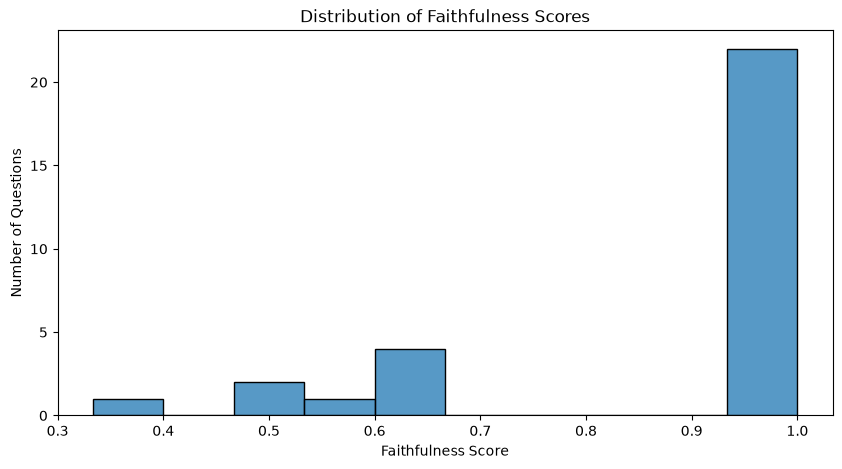

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eval_res,
    x="score",
    bins=10
)

plt.xlabel("Faithfulness Score")
plt.ylabel("Number of Questions")
plt.title("Distribution of Faithfulness Scores")
plt.show()

In [89]:
q = eval_res.loc[eval_res["score"] < 0.4, "question"].iloc[0]
a = merged_df[merged_df["question"] == q]["extracted_answers"].iloc[0]
reason = eval_res.loc[eval_res["score"] < 0.4, "reason"].iloc[0]
display(Markdown(f"""
{len(eval_res[eval_res["score"] < 0.4])} answers were scored lower than 0.4
#### Question:
{q}
#### Answer:
{a}
"""))




1 answers were scored lower than 0.4
#### Question:
What are the main limitations of electromagnetic induction?
#### Answer:
I don't have enough information in the provided context to answer the question about the main limitations of electromagnetic induction. The context appears to be related to machine learning and artificial intelligence, specifically discussing various models and techniques for anomaly detection and attribute alignment. There is no mention of electromagnetic induction.


In [91]:
filtered = eval_res[(eval_res["score"] > 0.5) & (eval_res["score"] < 0.7)]

q = filtered["question"].iloc[0]
reason = filtered["reason"].iloc[0]

a = merged_df.loc[merged_df["question"] == q, "extracted_answers"].iloc[0]

display(Markdown(f"""
{len(filtered)} answers were scored between 0.5 and 0.7

#### Question:
{q}
#### Answer:
{a}

#### Reason:
{reason}
"""))


5 answers were scored between 0.5 and 0.7

#### Question:
How does optical interference work?
#### Answer:
I don't have enough information in the provided context to answer the question about how optical interference works. The context appears to be related to adversarial attacks and content filtering, with no mention of optical interference.

#### Reason:
The score is 0.67 because the actual output incorrectly introduced topics such as few‑step generative models, protein structure generation, noise‑space reward alignment, and option pricing models, none of which are mentioned in the retrieval context that focuses on optical inter‑satellite links, satellite constellations, fiber optics, and quantum interference.


In [92]:
filtered = eval_res[eval_res["score"] == 1]

q = filtered["question"].iloc[0]
q2 = filtered["question"].iloc[2]
reason = filtered["reason"].iloc[0]
reason2 = filtered["reason"].iloc[2]

a = merged_df.loc[merged_df["question"] == q, "extracted_answers"].iloc[0]
a2 = merged_df.loc[merged_df["question"] == q2, "extracted_answers"].iloc[0]
display(Markdown(f"""
#### Question:
{len(filtered)} answers were scored 1

{q}
#### Answer:
{a}
#### Reason:
{reason}

#### Question:
{q2}
#### Answer:
{a2}
#### Reason:
{reason2}
"""))


#### Question:
22 answers were scored 1

What is the difference between RAM and disk storage?
#### Answer:
I don't have enough information in the provided context to answer the question. The context appears to be related to long-term agent memory, memory reading, and memory frameworks, but it does not mention RAM or disk storage.
#### Reason:
The score is 1.00 because there are no contradictions to indicate any misalignment between the actual output and the retrieval context. Great job!

#### Question:
How does distributed consensus algorithms work?
#### Answer:
The provided context does not contain a detailed explanation of how distributed consensus algorithms work. However, based on the information provided, we can infer that distributed consensus algorithms are used to achieve a common optimal point among multiple agents through individual computation and local communication.

The context mentions that the objective of distributed optimal consensus is to design a distributed controller that makes each agent's state or output reach a common optimal point through individual computation and local communication with neighboring agents. It also mentions that average consensus protocols are a key advantage of distributed systems and decision-making, where agents exchange and reveal their state information only to their neighbors.

The context also mentions that the consensus value corresponds to the average of all initial values, and that the system is said to perform distributed averaging when the consensus value is achieved. However, it does not provide a detailed explanation of how the consensus value is computed or updated.

To answer the question, I would need more information about the specific algorithm or protocol being used. However, based on the general information provided, it can be inferred that distributed consensus algorithms work by:

1. Each agent computing its own value or state based on local information.
2. The agents exchanging and sharing their values with their neighbors.
3. The neighbors averaging their values to compute a consensus value.
4. The consensus value being updated and propagated through the network.

However, without more specific information about the algorithm or protocol being used, it is difficult to provide a more detailed explanation of how distributed consensus algorithms work.
#### Reason:
The score is 1.00 because there are no contradictions to indicate any misalignment between the actual output and the retrieval context. Great job!
